# 工程机械行业周期性特征研究

## 项目简介
本项目基于2018年1月至2025年12月的月度数据，探究工程机械行业（以挖掘机国内销量为核心指标）的周期波动特征，并重点分析其与宏观需求指标（房屋新开工面积、基础设施投资）之间的联动关系与驱动逻辑。

## 数据来源：
1. 挖掘机国内销量（单月及累计）：中国工程机械工业协会。
3. 房屋新开工面积累计同比、基础设施投资累计同比：国家统计局。

## 分析框架：
- **第一步（清洗与口径）**：从单月绝对量探索季节性，推导并切换至累计同比口径，完成多源数据的时间轴对齐。
- **第二步（特征与波动）**：划分行业的景气周期阶段（上行/下行/过渡），并对比工程机械与宏观指标的波动率（标准差）差异。
- **第三步（驱动因素与悖论）**：利用相关系数与滚动相关性，对比全样本与分阶段（2018-2021 vs 2022-2025）的关联度，揭示辛普森悖论与驱动逻辑切换。
- **第四步（领先滞后检验）**：通过交叉相关函数（CCF）验证工程机械销量是宏观经济的先行、同步还是滞后指标。

## 核心发现：
- 工程机械销量呈现高弹性特征，波动率显著高于下游宏观指标。
- 房地产新开工是工程机械最稳定的核心驱动力，基建托底无法对冲地产下行（全样本与分阶段存在辛普森悖论）。
- 工程机械销量与宏观指标在月度频率上同步行动，是宏观经济的**同步指标**，而非领先指标。

## 目录
- [一、 数据获取与清洗](#一-数据获取与清洗)
- [二、 行业周期形态分析](#二-行业周期形态分析)
- [三、 波动特征分析](#三-波动特征分析)
- [四、 驱动因素分析：地产主导与辛普森悖论](#四-驱动因素分析地产主导与辛普森悖论)
- [五、 领先/滞后分析](#五-领先滞后分析)
- [六、 核心数据统计汇总](#六-核心数据统计汇总)
- [七、 分析结论与判断](#七-分析结论与判断)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

## 一、 数据获取与清洗

### 1.1 数据来源与对齐
本项目数据均来源于公开权威渠道：挖掘机国内销量来自中国工程机械工业协会；宏观指标（房屋新开工面积、基础设施投资）来自国家统计局。

由于统计局发布的基建投资数据仅包含累计同比且自2018年起才单独发布，因此我们将三个指标的时间轴对齐至 2018 年 2 月至 2025 年 12 月。

In [5]:
df_wide=pd.read_csv('../data/raw/01_excavator_sales_wide.csv',index_col=0)

df_wide.columns=[int(x) for x in df_wide.columns]
df_wide.index=[int(x.strip('月')) for x in df_wide.index]

df_long=df_wide.stack().reset_index()
df_long.columns=['month','year','domestic_sales']

df_long['date']=pd.to_datetime(df_long[['year','month']].assign(day=1))
df_long=df_long.sort_values('date').reset_index(drop=True)
df_long=df_long[['date','domestic_sales']]

print(f'共有{len(df_long)}个月数据')

共有144个月数据


In [6]:
df_long.to_csv('../data/processed/01_excavator_sales_long.csv', index=False)

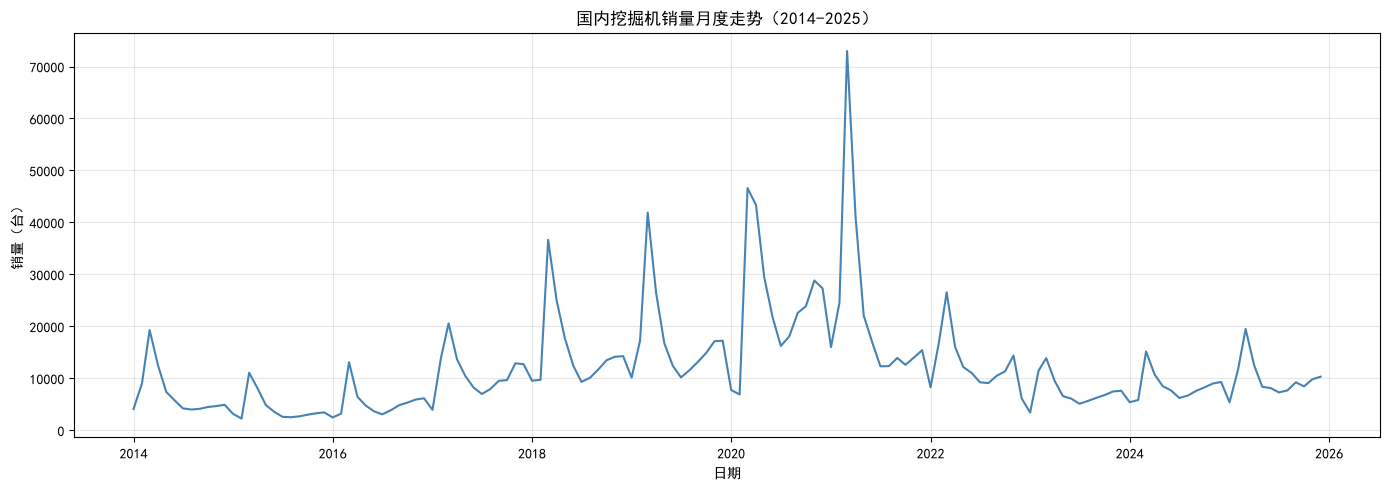

In [7]:
plt.figure(figsize=(14,5))
plt.plot(df_long['date'],df_long['domestic_sales'],color='steelblue')
plt.title('国内挖掘机销量月度走势（2014-2025）')
plt.xlabel('日期')
plt.ylabel('销量（台）')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 1.2 数据探索：季节性特征与口径切换

在进行宏观周期分析前，我们首先对挖掘机的单月国内销量进行探索性分析（见下文三张图）。

从“原始月度销量”图中可以明显看出，挖掘机销量存在极强的季节性周期：每年3-4月为传统旺季，1-2月受春节影响跌入谷底。如果直接使用单月绝对量观察，这种规律性的剧烈波动会严重掩盖宏观周期的真实走向。

进一步观察“同比增速”与“12个月移动平均”图可以发现：单月同比增速虽然剔除了部分季节性，但在2020年等基数异常年份极易出现极值（如增速突破300%或跌破-50%）；而12个月移动平均虽然能平滑波动、看清大趋势，但存在严重的滞后性。

**结论**：为了既剔除季节性，又消除单月基数扰动，同时保证三个指标频率的一致性，本文后续分析统一采用**累计同比口径**。

In [8]:
#同比增速
df_long['yoy']=df_long['domestic_sales'].pct_change(12)*100
#12月移动平均值
df_long['ma12']=df_long['domestic_sales'].rolling(12).mean()

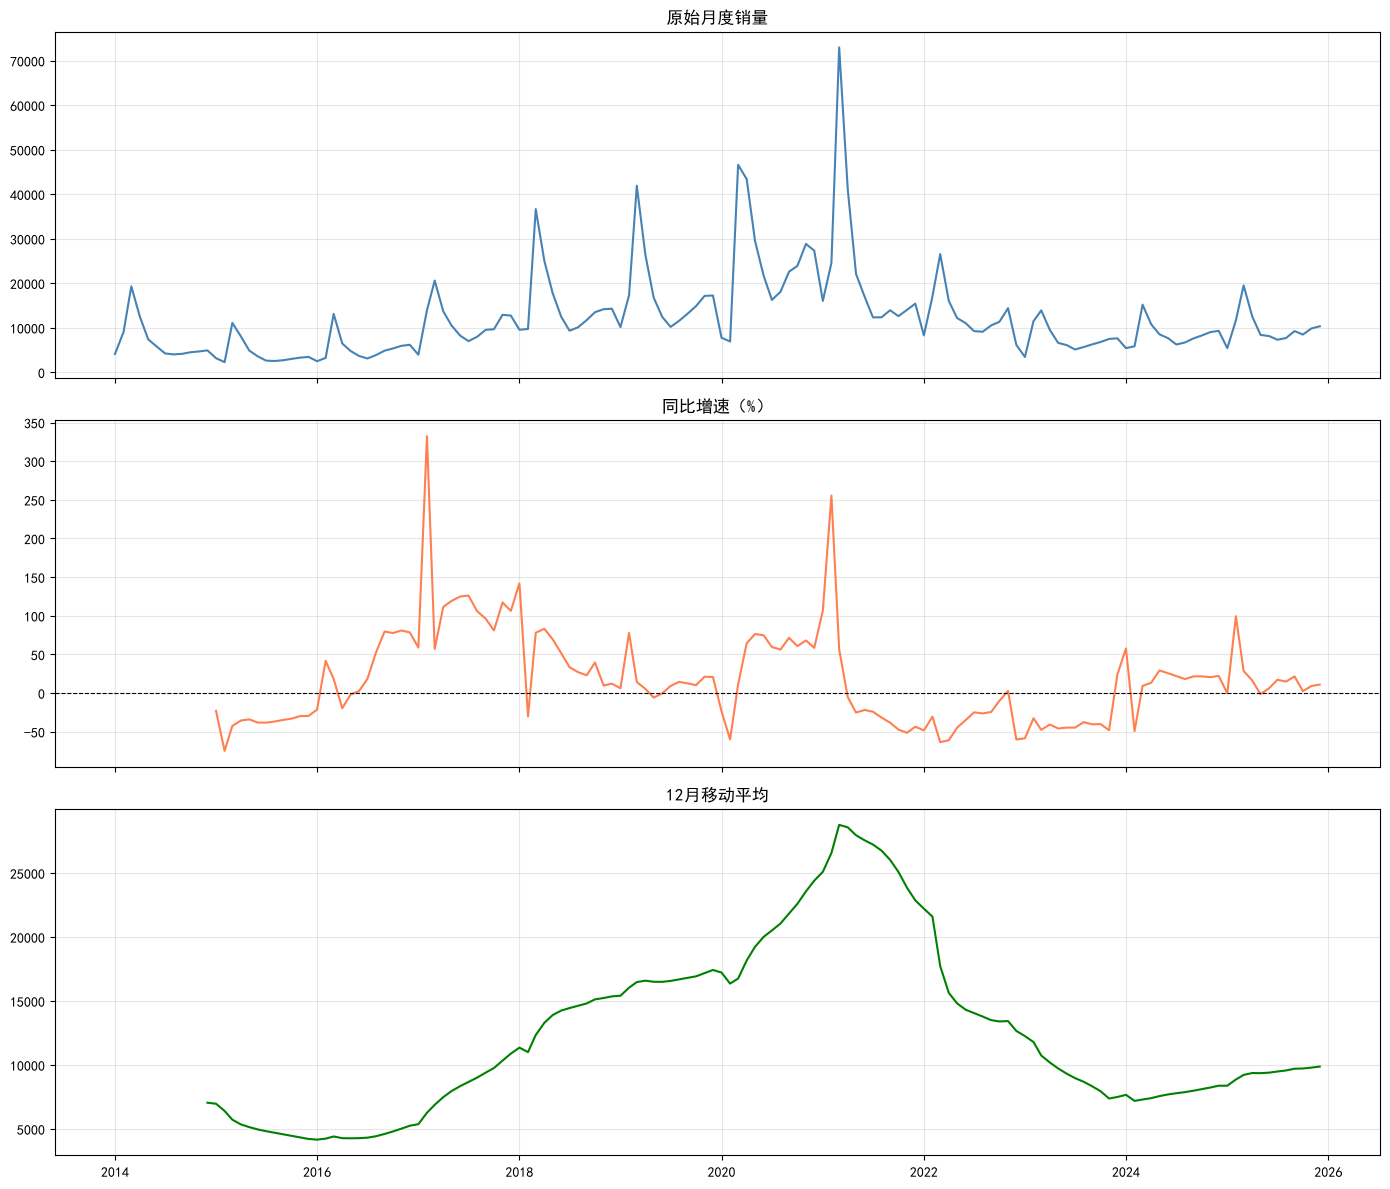

In [9]:
fig,axes=plt.subplots(3,1,figsize=(14,12),sharex=True)

axes[0].plot(df_long['date'],df_long['domestic_sales'],color='steelblue')
axes[0].set_title('原始月度销量')
axes[0].grid(alpha=0.3)

axes[1].plot(df_long['date'],df_long['yoy'],color='coral')
axes[1].axhline(0,color='black',linewidth=0.8,linestyle='--')
axes[1].set_title('同比增速（%）')
axes[1].grid(alpha=0.3)

axes[2].plot(df_long['date'],df_long['ma12'],color='green')
axes[2].set_title('12月移动平均')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
#读入数据
df_exc = pd.read_csv('../data/processed/01_excavator_sales_long.csv', parse_dates=['date'])
df_re = pd.read_csv('../data/raw/02_real_estate_new_start.csv', parse_dates=['date'])
df_infra = pd.read_csv('../data/raw/03_infra_investment.csv', parse_dates=['date'])

In [11]:
#清洗数据
df_exc['year']=df_exc['date'].dt.year
df_exc['month']=df_exc['date'].dt.month
df_exc['cum_sales']=df_exc.groupby('year')['domestic_sales'].cumsum()
df_exc['exc_cum_yoy']=df_exc['cum_sales'].pct_change(12)*100
df_exc=df_exc[df_exc['month']>1][['date','exc_cum_yoy']]

In [12]:
#合并
df_merge=df_exc.merge(df_re[['date','new_start_yoy']],how='inner',on='date')
df_merge=df_merge.merge(df_infra,how='inner',on='date')

print(f'对齐后共有{len(df_merge)}个月')
print(f'时间范围为{df_merge['date'].min()}到{df_merge['date'].max()}')
print(df_merge.head(20))
print(df_merge.tail(20))

对齐后共有88个月
时间范围为2018-02-01 00:00:00到2025-12-01 00:00:00
         date  exc_cum_yoy  new_start_yoy  infra_yoy
0  2018-02-01     7.892086            2.9       16.1
1  2018-03-01    45.450290            9.7       13.0
2  2018-04-01    55.340905            7.3       12.4
3  2018-05-01    57.725538           10.8        9.4
4  2018-06-01    57.006338           11.8        7.3
5  2018-07-01    54.888232           14.4        5.7
6  2018-08-01    52.302528           15.9        4.2
7  2018-09-01    49.370063           16.4        3.3
8  2018-10-01    48.463289           16.3        3.7
9  2018-11-01    44.229285           16.8        3.7
10 2018-12-01    41.100819           17.2        3.8
11 2019-02-01    42.290932            6.0        4.3
12 2019-03-01    23.956732           11.9        4.4
13 2019-04-01    18.190014           13.1        4.4
14 2019-05-01    13.854379           10.5        4.0
15 2019-06-01    12.266695           10.1        4.1
16 2019-07-01    12.024219            9.5   

如上所示，合并后的面板数据共有 88 个有效月度观测值。数据的时间跨度为 2018 年 2 月至 2025 年 12 月（统计局 1 月份免报）。

## 二、 行业周期形态分析

### 2.1 行业周期阶段划分

为了更精细地观测不同景气阶段下的指标表现，本文基于挖掘机累计同比的边际变化方向进行周期划分。具体规则为：若累计同比连续 3 个月上升，则定义为“上行期”；连续 3 个月下降，定义为“下行期”；其余震荡状态定义为“过渡期”。

需要说明的是，这里的“上行/下行”反映的是**景气度的边际变化（加速度）**，而非绝对销量水平。例如，2018-2019 年累计同比从 50% 回落至 10%，绝对量仍在增长，但增速在放缓，故被划分为“下行期”。

In [13]:
#分类函数
def classify_phase(series,window=3):
    phases=[]
    diff=series.diff()
    for i in range(len(series)):
        if i<window:
            phases.append('过渡')
            continue
        recent=diff.iloc[i-window:i+1]
        if all(recent>0):
            phases.append('上行')
        elif all(recent<0):
            phases.append('下行')
        else:
            phases.append('过渡')
    return phases
df_merge['phase']=classify_phase(df_merge['exc_cum_yoy'])
phase_stats=df_merge.groupby('phase')['exc_cum_yoy'].agg(['mean','std']).round(2)
phase_stats.index.name=None
phase_stats.columns=['均值','标准差']
print('各时期挖掘机统计量：')
print()
phase_stats

各时期挖掘机统计量：



,均值,标准差
上行,14.87,46.88
下行,11.58,28.19
过渡,0.27,40.62


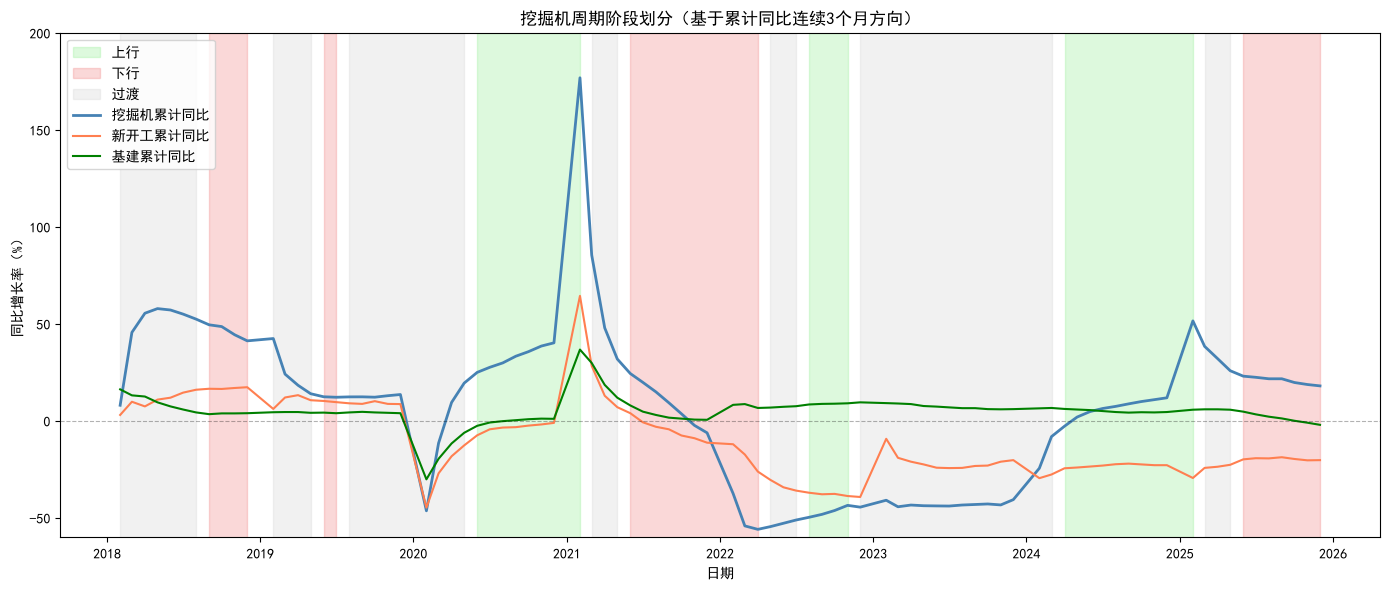

In [14]:
fig,ax=plt.subplots(figsize=(14,6))
colors={'上行':'lightgreen','下行':'lightcoral','过渡':'lightgrey'}
for phase,color in colors.items():
    mask=df_merge['phase']==phase
    ax.fill_between(df_merge['date'],-100,200,where=mask,color=color,alpha=0.3,label=phase)
ax.plot(df_merge['date'],df_merge['exc_cum_yoy'],color='steelblue',linewidth=2,label='挖掘机累计同比')
ax.plot(df_merge['date'],df_merge['new_start_yoy'],color='coral',linewidth=1.5,label='新开工累计同比')
ax.plot(df_merge['date'],df_merge['infra_yoy'],color='green',linewidth=1.5,label='基建累计同比')
ax.axhline(0,linestyle='--',color='black',alpha=0.3,linewidth=0.8)
ax.set_ylim(-60,200)
ax.set_xlabel('日期')
ax.set_ylabel('同比增长率（%）')
ax.legend(loc='upper left')
ax.set_title('挖掘机周期阶段划分（基于累计同比连续3个月方向）')
plt.tight_layout()
plt.savefig('../output/figures/01_trend_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

### 2.2 趋势初探与驱动逻辑分化
从三者累计同比的走势图（上图）可以看出，在 2018 年至 2021 年上半年，挖掘机销量、新开工面积与基建投资呈现高度的同向共振。三者均在 2020 年初受疫情冲击砸出深坑，随后在政策发力下迎来“深 V 型”反弹，并于 2021 年初同步见顶。

然而，2021 年下半年之后，三者走势出现显著分化：房地产新开工断崖式下跌，而基建投资在政策托底下逆势上行。挖掘机销量在此阶段出现剧烈下行，这暗示了行业背后的驱动逻辑可能发生了结构性切换。

## 三、 波动特征分析

### 3.1 高弹性的周期放大器

In [15]:
vol = df_merge[['exc_cum_yoy', 'new_start_yoy', 'infra_yoy']].std().round(2)
print(f"挖掘机标准差为 {vol['exc_cum_yoy']}")
print(f"新开工标准差为 {vol['new_start_yoy']}")
print(f"基建标准差为 {vol['infra_yoy']}")

挖掘机标准差为 39.64
新开工标准差为 19.09
基建标准差为 7.57


In [16]:
phase_vol = df_merge.groupby('phase')[['exc_cum_yoy', 'new_start_yoy', 'infra_yoy']].std().round(2)
phase_vol.index.name=None
phase_vol.columns.name=None
phase_vol.columns=['挖掘机','新开工','基建']
print('各时期三者标准差：')
print()
phase_vol

各时期三者标准差：



,挖掘机,新开工,基建
上行,46.88,21.99,7.72
下行,28.19,14.53,2.84
过渡,40.62,19.37,9.08


如上所示，从波动率（标准差）的对比来看，挖掘机累计同比（39.64）远高于房屋新开工面积（19.09）和基建投资（7.57），且在周期的各个阶段均保持最高波动。

这印证了工程机械作为**中游设备投资品的高弹性特征**：在下游需求扩张或收缩时，设备采购的推延或提前会放大宏观波动；同时，基建投资由于具备逆周期调节属性，其波动率被政策平滑，成为三者中最稳定的“压舱石”。

## 四、 驱动因素分析：地产主导与辛普森悖论

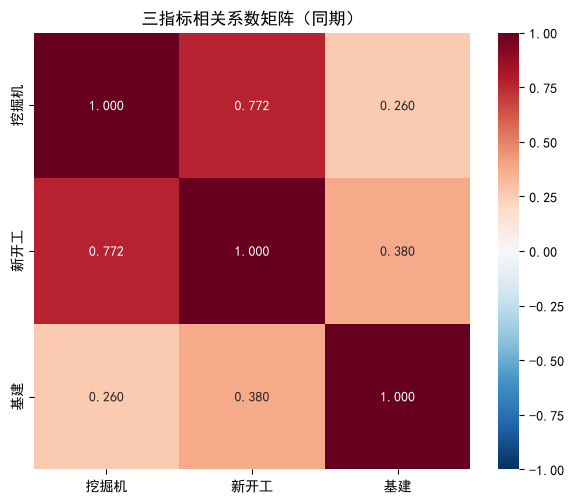

In [17]:
corr_matrix = df_merge[['exc_cum_yoy', 'new_start_yoy', 'infra_yoy']].corr()
corr_matrix.index=['挖掘机','新开工','基建']
corr_matrix.columns=['挖掘机','新开工','基建']

plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix,cmap='RdBu_r',center=0,vmin=-1,vmax=1,annot=True,fmt='.3f',square=True)
plt.title('三指标相关系数矩阵（同期）')
plt.tight_layout()
plt.savefig('../output/figures/02_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### 4.1 全样本视角：地产为核心驱动
如上表（热力图）所示，从全样本相关系数矩阵看，挖掘机累计同比与房屋新开工面积累计同比的相关系数高达 **0.772**（强相关），而与基建投资的相关系数仅为 **0.260**（弱相关）。

单从全样本数据来看，房地产新开工是决定工程机械行业景气度的核心驱动因素，而基建投资的拉动作用相对有限。

In [18]:
#计算各时期相关系数
corr_up_exc_re=df_merge[df_merge['phase']=='上行']['exc_cum_yoy'].corr(df_merge[df_merge['phase']=='上行']['new_start_yoy']).round(3)
corr_up_exc_infra=df_merge[df_merge['phase']=='上行']['exc_cum_yoy'].corr(df_merge[df_merge['phase']=='上行']['infra_yoy']).round(3)

corr_down_exc_re=df_merge[df_merge['phase']=='下行']['exc_cum_yoy'].corr(df_merge[df_merge['phase']=='下行']['new_start_yoy']).round(3)
corr_down_exc_infra=df_merge[df_merge['phase']=='下行']['exc_cum_yoy'].corr(df_merge[df_merge['phase']=='下行']['infra_yoy']).round(3)

corr_trans_exc_re = df_merge[df_merge['phase']=='过渡']['exc_cum_yoy'].corr(df_merge[df_merge['phase']=='过渡']['new_start_yoy']).round(3)
corr_trans_exc_infra = df_merge[df_merge['phase']=='过渡']['exc_cum_yoy'].corr(df_merge[df_merge['phase']=='过渡']['infra_yoy']).round(3)

print('各时期相关系数：')
print()
print(f'上行期：挖掘机-新开工 r={corr_up_exc_re}；挖掘机-基建 r={corr_up_exc_infra}')
print(f'下行期：挖掘机-新开工 r={corr_down_exc_re}；挖掘机-基建 r={corr_down_exc_infra}')
print(f'过渡期：挖掘机-新开工 r={corr_trans_exc_re}；挖掘机-基建 r={corr_trans_exc_infra}')

各时期相关系数：

上行期：挖掘机-新开工 r=0.93；挖掘机-基建 r=0.477
下行期：挖掘机-新开工 r=0.556；挖掘机-基建 r=-0.389
过渡期：挖掘机-新开工 r=0.802；挖掘机-基建 r=0.267


如上所示，在上行期和过渡期，挖掘机与新开工都是强相关，而与基建三时期都为弱相关

### 4.2 辛普森悖论与驱动逻辑切换
全样本的高相关性可能掩盖了时间维度上的结构性突变。接下来，我们按时间轴（以 2022 年为界）拆分样本，重新测算相关系数。

In [19]:
df_phase1 = df_merge[df_merge['date'] < '2022-01-01']
df_phase2 = df_merge[df_merge['date'] >= '2022-01-01']

print('分阶段相关系数:')
print()
for period,df_phase in [('2018-2021',df_phase1),('2022-2025',df_phase2)]:
    corr1=df_phase['exc_cum_yoy'].corr(df_phase['new_start_yoy'])
    corr2=df_phase['exc_cum_yoy'].corr(df_phase['infra_yoy'])
    corr3=df_phase['new_start_yoy'].corr(df_phase['infra_yoy'])
    print(f'{period}:挖掘机-新开工 r={corr1:.3f}；挖掘机-基建 r={corr2:.3f}；新开工-基建 r={corr3:.3f}')

分阶段相关系数:

2018-2021:挖掘机-新开工 r=0.838；挖掘机-基建 r=0.776；新开工-基建 r=0.873
2022-2025:挖掘机-新开工 r=0.313；挖掘机-基建 r=-0.695；新开工-基建 r=-0.380


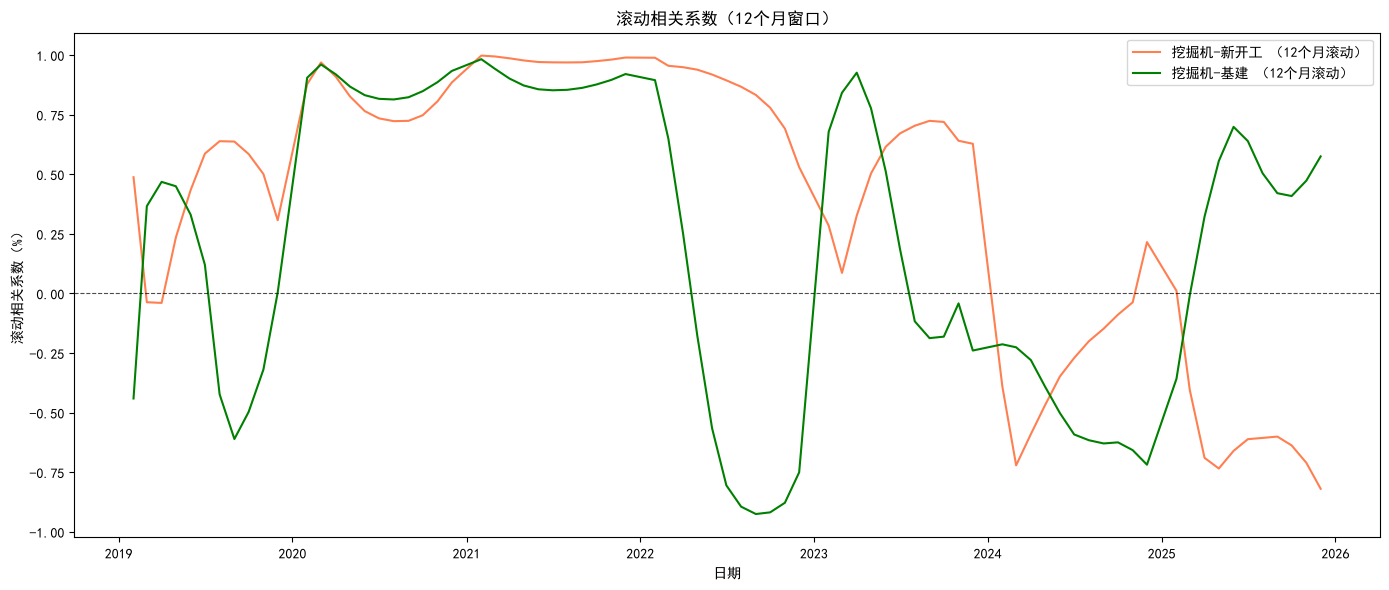

In [20]:
df_merge['rolling_corr_exc_re']=df_merge['exc_cum_yoy'].rolling(12).corr(df_merge['new_start_yoy'])
df_merge['rolling_corr_exc_infra']=df_merge['exc_cum_yoy'].rolling(12).corr(df_merge['infra_yoy'])

fig,ax=plt.subplots(figsize=(14,6))
ax.plot(df_merge['date'],df_merge['rolling_corr_exc_re'],color='coral',label='挖掘机-新开工 （12个月滚动）')
ax.plot(df_merge['date'],df_merge['rolling_corr_exc_infra'],color='green',label='挖掘机-基建 （12个月滚动）')
ax.set_title('滚动相关系数（12个月窗口）')
ax.axhline(0,color='black',linestyle='--',linewidth=0.8,alpha=0.7)
ax.set_xlabel('日期')
ax.set_ylabel('滚动相关系数（%）')
ax.legend()
plt.tight_layout()
plt.savefig('../output/figures/03_rolling_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

如上图以及前面的分阶段测算结果，我们发现了经典的**辛普森悖论**：
- **2018-2021 年（共振期）**：挖机与新开工、基建的相关系数分别高达 0.838 和 0.776，地产与基建共同拉动了设备需求。
- **2022-2025 年（分化期）**：地产暴雷导致新开工下行，基建作为托底工具逆势上行。此时挖机与新开工相关系数降至 0.313，与基建更是转为强负相关（-0.695）。这说明**基建托底无法对冲地产下行对通用工程机械的拖累**。

观察 12 个月滚动相关系数图，可以更直观地看到这一突变：2021 年之前，相关曲线几乎维持在 1.0 的极高水平；而 2022 年之后，两条曲线出现剧烈分化与震荡，原有的驱动逻辑被打破，行业进入多因素博弈阶段。

## 五、 领先/滞后分析

In [21]:
def cross_correlation(x,y,maxlag=6):
    '''
    x:领先候选指标
    y:滞后候选指标
    maxlag:最大位移量
    lag:领先量，正数代表领先
    '''
    results=[]
    for lag in range(-maxlag,maxlag+1):
        corr=x.shift(lag).corr(y)
        results.append({'lag':lag,'corr':corr})
    return pd.DataFrame(results)
ccf_exc_re=cross_correlation(df_merge['exc_cum_yoy'],df_merge['new_start_yoy'])
ccf_exc_infra=cross_correlation(df_merge['exc_cum_yoy'],df_merge['infra_yoy'])
ccf_re_infra=cross_correlation(df_merge['new_start_yoy'],df_merge['infra_yoy'])

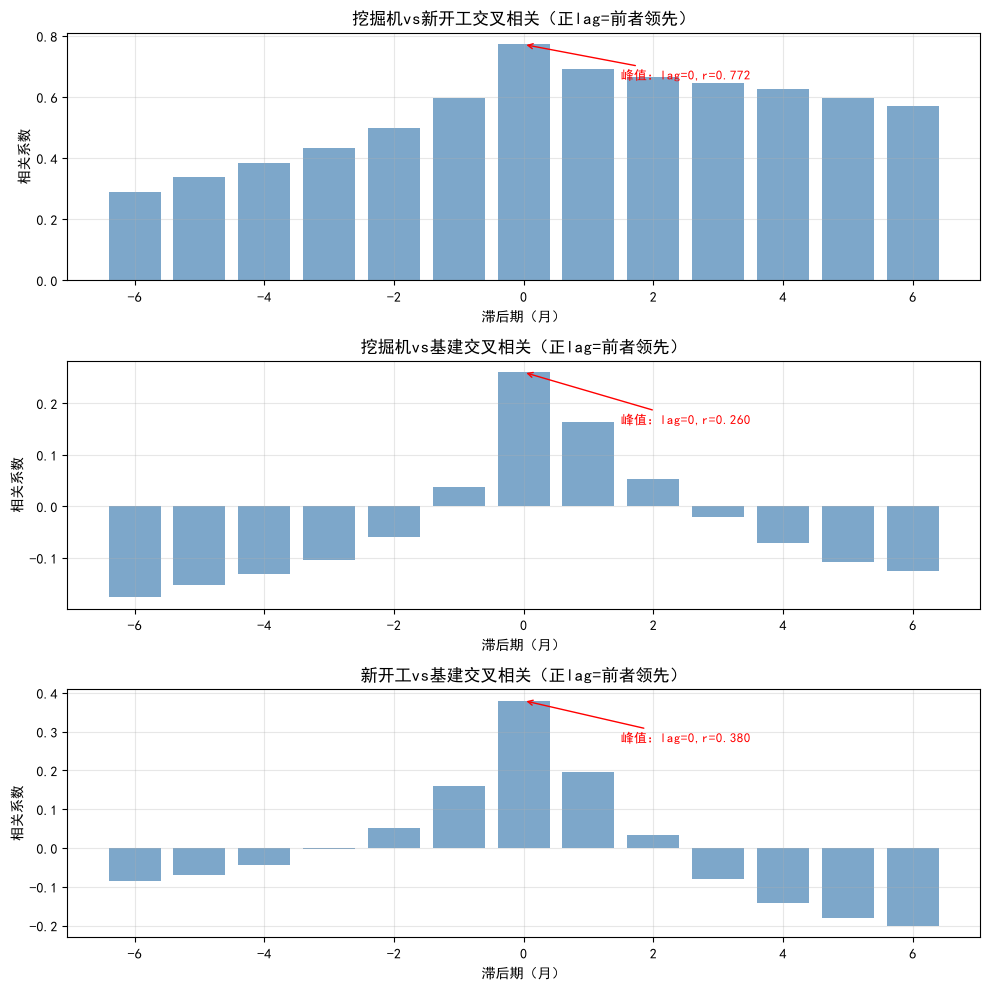

In [22]:
fig,axes=plt.subplots(3,1,figsize=(10,10))
for ax,ccf,title in zip(axes,
                        [ccf_exc_re,ccf_exc_infra,ccf_re_infra],
                        ['挖掘机vs新开工','挖掘机vs基建','新开工vs基建']):
    ax.bar(ccf['lag'],ccf['corr'],color='steelblue',alpha=0.7)
    ax.set_title(f'{title}交叉相关（正lag=前者领先）')
    ax.set_xlabel('滞后期（月）')
    ax.set_ylabel('相关系数')
    ax.grid(alpha=0.3)
    max_idx=ccf['corr'].abs().idxmax()
    ax.annotate(f'峰值：lag={ccf.loc[max_idx,'lag']},r={ccf.loc[max_idx,'corr']:.3f}',
                xy=(ccf.loc[max_idx,'lag'],ccf.loc[max_idx,'corr']),
                xytext=(ccf.loc[max_idx,'lag']+1.5,ccf.loc[max_idx,'corr']-0.08),
                color='red',
                ha='left', va='top',
                fontsize=9,
                arrowprops={'arrowstyle':'->','color':'red','lw':1})
plt.tight_layout()
plt.savefig('../output/figures/04_cross_correlation.png', dpi=300, bbox_inches='tight')
plt.show()

如上图所示，交叉相关函数（CCF）的结果显示，挖掘机与新开工、基建的相关系数均在滞后 0 期（lag=0）达到峰值。这意味着三个指标在月度频率上是同步行动的，工程机械销量不存在稳定的领先或滞后性。

它既是宏观需求落地的直接结果，受政策刺激立刻放量；又因累计同比本身平滑了单月扰动，难以体现出前瞻性。因此，工程机械销量是宏观经济的**同步指标**，可以作为观测景气度的同步印证，但不能作为预测的先行指标。

## 六、 核心数据统计汇总

为了直观呈现各项分析的最终结果，我们将上述全样本、分阶段视角的核心数据汇总如下：

In [23]:
df_merge.to_csv('../data/processed/02_merged_indicators.csv', index=False)

In [24]:
df_stats=df_merge.groupby('phase').apply(lambda g:pd.Series({
    '挖掘机-新开工':g['exc_cum_yoy'].corr(g['new_start_yoy']).round(3),
    '挖掘机-基建':g['exc_cum_yoy'].corr(g['infra_yoy']).round(3),
    '挖掘机波动率':g['exc_cum_yoy'].std().round(3),
    '样本量':                   len(g)
}))
df_stats.index=['上行期','下行期','过渡期']
full= pd.Series({
    '挖掘机-新开工': df_merge['exc_cum_yoy'].corr(df_merge['new_start_yoy']).round(3),
    '挖掘机-基建':   df_merge['exc_cum_yoy'].corr(df_merge['infra_yoy']).round(3),
    '挖掘机波动率': df_merge['exc_cum_yoy'].std().round(3),
    '样本量':        len(df_merge)
}, name='全样本')
df_stats=pd.concat([df_stats,full.to_frame().T])
df_stats['样本量']=df_stats['样本量'].astype('int')
df_stats.name='相关系数'
df_stats

,挖掘机-新开工,挖掘机-基建,挖掘机波动率,样本量
上行期,0.930,0.477,46.877,22
下行期,0.556,-0.389,28.192,23
过渡期,0.802,0.267,40.617,43
全样本,0.772,0.260,39.641,88


In [26]:
df_stats.to_csv('../output/tables/01_summary_statistics.csv')

## 七、分析结论与判断

如上表所示，无论处于何种阶段，挖掘机与新开工的相关性（0.930 / 0.556 / 0.802）始终高于基建。特别是在下行期，挖机与基建的负相关性（-0.389）进一步凸显了地产主导的逻辑。结合波动率数据，挖掘机在各阶段的波动都显著大于宏观指标。

**1. 周期形态与数据选择**
为剔除极强的季节性干扰，本文采用累计同比口径。样本期（2018-2025）跨越了上一轮周期的尾部与新一轮周期的复苏起点。期间经历了：2018-2019 高位增速放缓、2020 年疫情深坑与 V 型激增、2021-2023 景气收敛与绝对量收缩、2024-2025 企稳复苏。

**2. 波动特征**
挖掘机累计同比的波动率（39.64）远高于新开工（19.09）和基建（7.57）。这印证了工程机械作为中游设备投资品的高弹性特征，而基建投资受逆周期调节政策平滑，波动最小。

**3. 驱动因素与辛普森悖论**
全样本视角下，挖机与新开工高度相关（r=0.772），与基建弱相关（r=0.260）。但分阶段来看存在辛普森悖论：2021 年之前地产与基建共振；2022 年之后地产暴雷、基建托底，挖机与基建转为强负相关（-0.695）。这说明基建托底无法对冲地产下行对通用挖机的拖累，房地产新开工始终是最核心驱动力。

**4. 领先/滞后**
交叉相关分析（CCF）显示，峰值均在 lag=0 处，不存在稳定的领先或滞后关系。工程机械销量在月度频率上是宏观经济的**同步指标**。

**5. 局限性与展望**
本文样本期未能覆盖完整的 8-10 年朱格拉周期；且未纳入设备更新换代周期（存量替换）和出口数据。2024-2025 年挖机的逆势复苏，可能源于出口拉动或存量设备更新，这是未来可进一步拆解分析的方向。